In [1]:
import numpy as np
import pandas as pd
from pandas import Series, DataFrame
import matplotlib.pyplot as plt
np.set_printoptions(legacy='1.21')

In [2]:
#The valuation of bonds. Present and forward values.
#In this case FV is the value to be paid n periods from now, r is the interest rate per period
#and n is the number of periods

def pvdiscr(FV,r,n):
    return FV/((1+r)**n)

pvdiscr(1000,0.04,9)

702.5867355788306

In [3]:
#Formula for the continuous time case.
def pvcts(FV,r,T):
    return FV*np.exp(-r*T)
pvcts(100,0.10,2)

81.87307530779819

In [4]:
#Formula for a perpetuity paying C every period
def pvperp(C,r):
    return C/r
pvperp(1,0.05)

20.0

In [5]:
#formula for an annuity, paying C each period for N periods.
def pvann(C,r,N):
    return (C/r)*(1- (1/(1+r))**N)
pvann(1,0.05,10)

7.72173492918482

In [6]:
#Direct calculation
pv=[1/(1+0.05)**i for i in range(1,11)]
print(pv)
sum(pv)

[0.9523809523809523, 0.9070294784580498, 0.863837598531476, 0.8227024747918819, 0.7835261664684589, 0.7462153966366274, 0.7106813301301214, 0.676839362028687, 0.6446089162177971, 0.6139132535407591]


7.7217349291848105

In [7]:
#Alternative formula for an annuity.
def pvann2(C,r,N):
    p=[C/(1+r)**i for i in range(1,N+1)]
    return sum(p)
pvann2(1,0.05,10)

7.7217349291848105

In [8]:
for i in range(1,7):
    print(pvann(1,0.05,i))

0.9523809523809534
1.8594104308390036
2.723248029370482
3.545950504162363
4.329476670630823
5.075692067267452


In [9]:
for i in range(1,7):
    print(pvann2(1,0.05,i))

0.9523809523809523
1.8594104308390023
2.7232480293704784
3.5459505041623602
4.329476670630819
5.075692067267446


In [10]:
#Let r be the annual percentage rate (APR)
#What is the Effective Annual Rate with k payments per year)
#(1+y)=(1+(r/k))**k
def ear(r,k):
    y=(1+(r/k))**k-1
    return y

print(ear(0.1,1))
print(ear(0.1,4))
print(ear(0.1,12))
print(np.exp(0.1))

0.10000000000000009
0.10381289062499954
0.10471306744129683
1.1051709180756477


In [11]:
#The price of a bond is the sum of PV of coupons and the Face Value
def bondprice(C,FV,r,N):
    return pvann2(C,r,N)+FV/(1+r)**N
bondprice(3,100,0.03,8)

99.99999999999999

In [12]:
#Formula for an annuity with less-than-annual payments
#Alternative formula for an annuity.
def pvannk(C,k,r,N):
    p=[(C/k)/(1+(ear(r,k)/k))**i for i in range(1,N*k+1)]
    return sum(p)
#print(pvannk(1,2,0.05,1))
#print(pvann2(1,0.05,1))
print(ear(0.05,1))
print(ear(0.05,2))
print(pvannk(1,2,0.05,1))
print(pvannk(1,1,0.05,1))
print(pvann2(1,0.05,1))

0.050000000000000044
0.05062499999999992
0.9632733458114711
0.9523809523809523
0.9523809523809523


In [13]:
#The price of a bond when coupons are paid k times per year and r is APR
def bondpricek(C,k,FV,r,N):
    return pvannk(C,k,r,N)+FV/(1+ear(r,k)/k)**(N*k)
print(bondpricek(ear(0.03,2)*100,2,100,ear(0.03,2),1))
print(bondpricek(3,2,100,0.03,1))
print(bondprice(3,100,0.03,1))

99.97767248022889
99.97799996011798
99.99999999999999


In [14]:
#The price of a bond when coupons are paid k times per year and r is APR
def bondpricek(C,k,FV,r,N):
    return pvannk(C,k,r,N)+FV/(1+ear(r,k)/k)**(N*k)
print(bondpricek(ear(0.03,2)*100,2,100,ear(0.03,2),1))
print(bondpricek(3,2,100,0.03,1))
print(bondprice(3,100,0.03,1))

99.97767248022889
99.97799996011798
99.99999999999999


In [15]:
#Computing forward values. 
#Simple trick: the forward value at time N is just the present value times (1+r)**N
def fwann(C,r,N):
    return pvann2(C,r,N)*((1+r)**N)
fwann(1,0.05,2)

2.0500000000000003

In [16]:
#Alternative way to compute forward value.
def fwann2(C,r,N):
    p=[C*(1+r)**i for i in range(0,N)]
    return sum(p)
fwann2(10000,0.05,35)

903203.0735184505

In [17]:
from scipy.optimize import fsolve 

# Define the nonlinear equation: x^2 - 4 = 0
def equation(x):
    return x**2 - 4

# Provide an initial guess
initial_guess = 1.0

# Solve the equation
solution = fsolve(equation, initial_guess)

solution

array([2.])

In [18]:
#Notice that the fsolve algorithm give you only one solution, usually the one 
#closer to the initial guess. With multiple initial guesses you can find
#multiple solutions.

roots = []
for guess in [ -1.5, 1.5]:
    root = fsolve(equation, guess)[0] #[0] takes the first element of the array.
    roots.append(root)

roots=set(roots)
print(roots)

{2.0, -2.0}


In [19]:
#Finding the YTM of a bond
#Define the nonlinear equation: 5/(1+x) + 105/(1+x)**2 - 98 = 0
def equation1(x):
    return 5/(1+x) + 105/(1+x)**2 - 98


# Provide an initial guess
initial_guess = 0

# Solve the equation
solution = fsolve(equation1, initial_guess)

solution

array([0.06092285])

In [20]:
bondprice(5,100,0.06092285,2)

97.99999953098076

In [21]:
def YTM(C,FV,N,P,guess):
    def equation1(x):
        return bondprice(C,FV,x,N) - P
    return fsolve(equation1,guess)

In [22]:
YTM(5,100,2,98,1)

array([0.06092285])

In [23]:
YTM(5,100,2,98,1)[0]

0.06092284739871109

In [24]:
#Showing the change in bond price as interest rates change
x=[bondprice(5,100,i/10000,4) for i in range(0,3000)]
print(x[0:5])
print(x[2999])

[120.0, 119.95501099782538, 119.91004398260606, 119.86509894130562, 119.82017586089673]
45.85657342253444


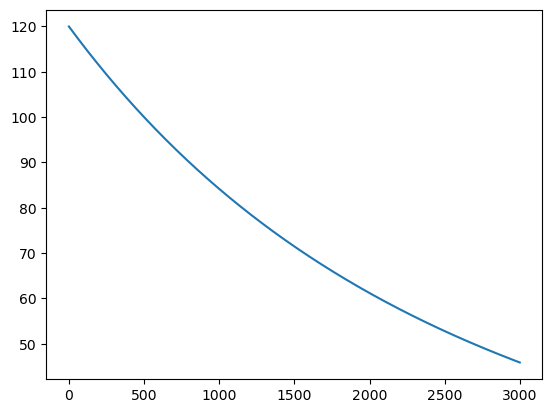

In [25]:
plt.plot(x)

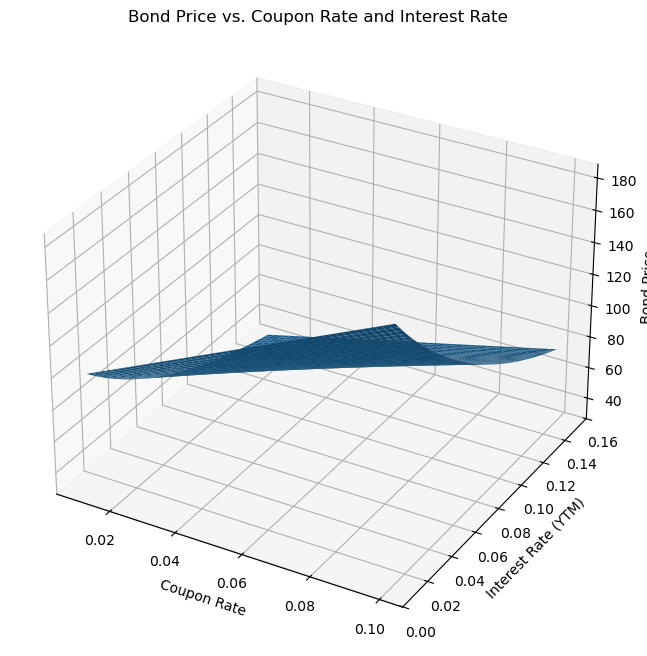

In [26]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create arrays for coupon rate and interest rate
coupon_rates = np.linspace(0.01, 0.10, 50)  # From 1% to 10%
interest_rates = np.linspace(0.01, 0.15, 50) # From 1% to 15%

# Create a meshgrid for the 3D plot
cr, ir = np.meshgrid(coupon_rates, interest_rates)
# Calculate bond prices for each combination of coupon rate and interest rate

prices = np.array([[bondprice(cr*100, 100, ir, 10) for cr in coupon_rates] for ir in interest_rates])

# Create the 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
ax.plot_surface(cr, ir, prices) #, cmap='viridis')

# Set labels for the axes
ax.set_xlabel('Coupon Rate')
ax.set_ylabel('Interest Rate (YTM)')
ax.set_zlabel('Bond Price')
ax.set_title('Bond Price vs. Coupon Rate and Interest Rate')

plt.show()

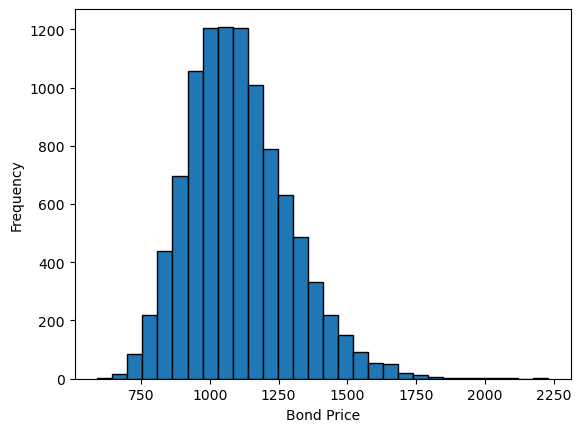

In [27]:
#Simulate 10000 random yields from N(0.03, 0.02) and 
#estimate the distribution of prices for a 10-year, 4% coupon, $1000 face bond.
#The simulation estimates a mean price around $1085 with variance induced by yield shocks.

import matplotlib.pyplot as plt
rates = np.random.normal(0.03, 0.02, 10000)
prices = [bondprice(40,1000, r, 10) for r in rates]

plt.hist(prices, bins=30, edgecolor='k')
plt.xlabel("Bond Price")
plt.ylabel("Frequency")
plt.show()

In [28]:
#Computing the duration of a bond
#(Macaulay) duration is the elasticity of the bond price to 1+YTM
def duration(C,FV,r,N):
    return sum(i*((C/(1+r)**i)/bondprice(C,FV,r,N)) for i in range(0,N))+N*(FV/(1+r)**N)/bondprice(C,FV,r,N)
duration(5,100,0.05,3)

2.729834791059281

In [29]:
#Duration when payments are less than annual
def durationk(C,k,FV,r,N):
    return sum(i*((C/k)/(1+r)**i)/bondpricek(C,k,FV,r,N) for i in range(0,N*k))+N*(FV/(1+ear(r,k))**N)/bondpricek(C,k,FV,r,N)
print(duration(5,100,0.05,3))
print(durationk(5,1,100,0.05,3))

2.729834791059281
2.729834791059281
